# Fase 2 · Preprocesamiento, ingeniería de variables y modelo base
**Proyecto Integrador de Ciencia de Datos e Inteligencia Artificial** · Universidad de La Salle · Maestría en Inteligencia Artificial
**Predicción de diabetes y segmentación de perfiles de riesgo (BRFSS 2023)** · Alain Alexander Camacho Prado · Entregable 2 (15 de noviembre de 2026)

Este cuaderno se ejecuta de principio a fin (`Kernel > Restart & Run All`) con el archivo `cdc_brfss_diabetes_2023.csv` en la misma carpeta y las versiones indicadas en `requirements.txt`.

**Contenido**
1. Carga y verificación del conjunto de datos
2. Calidad de datos: valores faltantes y duplicados
3. Partición estratificada Train / Validación / Prueba *(se ejecuta antes de ajustar cualquier transformación, para evitar fuga de datos)*
4. Tratamiento de valores atípicos (winsorization)
5. Experimento de imputación bajo MCAR, MAR y MNAR
6. Ingeniería de variables
7. Codificación y escalamiento dentro de un `Pipeline`
8. Tratamiento del desbalance de clases
9. Modelo base de clasificación (diabetes)
10. Modelo base de regresión (IMC)
11. Exportación de artefactos y lista de chequeo

In [1]:
# ---- 0. Configuración general ----
import json, warnings, platform
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib as mpl
import seaborn as sns, sklearn, imblearn, joblib
from scipy import stats

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix, roc_curve, precision_recall_curve,
                             r2_score, mean_squared_error, mean_absolute_error)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

warnings.filterwarnings("ignore")
RANDOM_STATE = 42                      # semilla única para todo el cuaderno (reproducibilidad)
np.random.seed(RANDOM_STATE)
DATA_PATH = Path("../data/raw/cdc_brfss_diabetes_2023.csv")
FIG = Path("../reports/figuras/fase2"); FIG.mkdir(parents=True, exist_ok=True)
ART = Path("../reports/artefactos_fase2"); ART.mkdir(parents=True, exist_ok=True)
RES = {}                               # resultados numéricos que alimentan el informe

AZUL, MENTA, CELESTE, TINTA, GRIS, FONDO = "#184f95", "#27b88e", "#6fa2e8", "#1a1a1a", "#444444", "#eef1f4"
sns.set_theme(style="ticks", rc={"font.family": ["Arial", "Liberation Sans", "DejaVu Sans"], "font.size": 9.5,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False, "axes.edgecolor": "#3d3d3d",
    "axes.labelcolor": "#222222", "axes.labelsize": 9.5, "xtick.labelsize": 9, "ytick.labelsize": 9, "ytick.major.size": 0,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#ffffff", "grid.linewidth": 1.1, "axes.axisbelow": True,
    "legend.fontsize": 9, "legend.frameon": False, "figure.facecolor": FONDO, "axes.facecolor": FONDO,
    "savefig.facecolor": FONDO, "savefig.dpi": 220, "savefig.bbox": "tight", "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlecolor": AZUL, "axes.titlelocation": "left", "axes.titlepad": 10})
import logging; logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
es = lambda x, d=0: f"{x:,.{d}f}".replace(",", "X").replace(".", ",").replace("X", ".")
print("Python", platform.python_version(), "| pandas", pd.__version__, "| numpy", np.__version__,
      "| scikit-learn", sklearn.__version__, "| imbalanced-learn", imblearn.__version__)

Python 3.13.18 | pandas 3.0.5 | numpy 2.5.3 | scikit-learn 1.9.1 | imbalanced-learn 0.14.2


## 1. Carga y verificación del conjunto de datos
Antes de transformar los datos se verifica que el archivo coincide con lo descrito en la Fase 1. La verificación se hace sobre el archivo completo porque no ajusta ningún parámetro que luego use un modelo.

In [2]:
df = pd.read_csv(DATA_PATH)
print("Dimensiones:", df.shape)
assert (df == df.round()).all().all(), "Hay valores no enteros"
df = df.astype("int16")                               # todas las columnas son códigos enteros: se reduce memoria
TARGET_CLF, TARGET_REG = "Diabetes_binary", "BMI"

verif = pd.DataFrame({
    "Reportado en Fase 1": ["272.270", "18", "0", "0", "85,40 % / 14,60 %", "28,71 / 27,00", "12 – 98", "18.743 (6,88 %)", "47,0", "1 – 6", "1 – 8"],
    "Verificado en Fase 2": [es(len(df)), str(df.shape[1]), es(int(df.isna().sum().sum())), es(int(df.duplicated().sum())),
        f"{es(100*(df[TARGET_CLF]==0).mean(),2)} % / {es(100*(df[TARGET_CLF]==1).mean(),2)} %",
        f"{es(df.BMI.mean(),2)} / {es(df.BMI.median(),2)}", f"{df.BMI.min()} – {df.BMI.max()}",
        (lambda q1,q3: f"{es(int((df.BMI>q3+1.5*(q3-q1)).sum()))} ({es(100*(df.BMI>q3+1.5*(q3-q1)).mean(),2)} %)")(*df.BMI.quantile([.25,.75])),
        es(df.BMI.quantile(.99),1), f"{df.Education.min()} – {df.Education.max()}", f"{df.Income.min()} – {df.Income.max()}"]},
    index=["Registros", "Variables", "Valores faltantes", "Duplicados exactos", "Clases (no / sí)", "IMC: media / mediana",
           "IMC: rango", "IMC: atípicos por IQR", "IMC: percentil 99", "Education: códigos", "Income: códigos"])
RES["verificacion"] = verif.reset_index(names="Aspecto").to_dict("records")
RES["n_total"] = len(df); RES["prev_total"] = float(df[TARGET_CLF].mean())
verif

Dimensiones: (272769, 18)


,Reportado en Fase 1,Verificado en Fase 2
Registros,272.270,272.769
Variables,18,18
Valores faltantes,0,0
Duplicados exactos,0,33.805
Clases (no / sí),"85,40 % / 14,60 %","85,38 % / 14,62 %"
IMC: media / mediana,"28,71 / 27,00","28,81 / 28,00"
IMC: rango,12 – 98,12 – 100
IMC: atípicos por IQR,"18.743 (6,88 %)","6.935 (2,54 %)"
IMC: percentil 99,"47,0","50,0"
Education: códigos,1 – 6,2 – 6


**Lectura.** El archivo contiene 272.769 registros y 18 variables. Varias cifras difieren de las reportadas en la Fase 1 (número de registros, duplicados exactos, estadísticos del IMC y rango de `Education` e `Income`). Todas las decisiones de esta fase se toman con los valores verificados aquí.

## 2. Calidad de datos: valores faltantes y duplicados
### 2.1 Valores faltantes y mecanismo de ausencia
La guía prohíbe imputar sin analizar el mecanismo de falta (MCAR, MAR o MNAR). Se revisan tres cosas: (a) valores nulos explícitos, (b) códigos centinela del BRFSS que equivalen a «no sabe / no responde» y (c) categorías del cuestionario original que no aparecen en el archivo.

In [3]:
nulos = df.isna().sum()
dominio = {  # valores válidos según el libro de códigos de la versión curada del BRFSS
    "GenHlth": range(1, 6), "MentHlth": range(0, 31), "PhysHlth": range(0, 31), "Age": range(1, 14),
    "Education": range(1, 7), "Income": range(1, 12), "BMI": range(12, 100)}
binarias = ["Diabetes_binary", "HighBP", "HighChol", "CholCheck", "Smoker", "Stroke", "HeartDiseaseorAttack",
            "PhysActivity", "NoDocbcCost", "DiffWalk", "Sex"]
dominio.update({b: (0, 1) for b in binarias})
fuera = {c: int((~df[c].isin(list(v))).sum()) for c, v in dominio.items()}
calidad = pd.DataFrame({"Nulos": nulos, "% nulos": 100 * nulos / len(df), "Fuera de dominio": pd.Series(fuera),
                        "Valores distintos": df.nunique(), "Mín.": df.min(), "Máx.": df.max()})
RES["faltantes_total"] = int(nulos.sum()); RES["fuera_dominio"] = {k: v for k, v in fuera.items() if v > 0}
RES["educ_valores"] = sorted(df.Education.unique().tolist()); RES["income_valores"] = sorted(df.Income.unique().tolist())
print("Nulos totales:", int(nulos.sum()), "| Registros fuera de dominio:", RES["fuera_dominio"])
print("Códigos presentes en Education:", RES["educ_valores"], "| Income:", RES["income_valores"])
calidad

Nulos totales: 0 | Registros fuera de dominio: {'BMI': 2}
Códigos presentes en Education: [2, 4, 5, 6] | Income: [1, 2, 3, 4, 5, 6, 7]


,Nulos,% nulos,Fuera de dominio,Valores distintos,Mín.,Máx.
Age,0,0.0,0,13,1,13
BMI,0,0.0,2,85,12,100
CholCheck,0,0.0,0,2,0,1
Diabetes_binary,0,0.0,0,2,0,1
DiffWalk,0,0.0,0,2,0,1
Education,0,0.0,0,4,2,6
GenHlth,0,0.0,0,5,1,5
HeartDiseaseorAttack,0,0.0,0,2,0,1
HighBP,0,0.0,0,2,0,1
HighChol,0,0.0,0,2,0,1


**Análisis del mecanismo.** No hay valores nulos ni códigos centinela (7, 9, 77, 99) en ninguna variable. Esto no significa que la encuesta original estuviera completa: el BRFSS registra «no sabe» y «se niega a responder», y el proveedor del archivo eliminó esos registros por lista (*listwise deletion*). En consecuencia:

- Sobre el archivo curado **no es posible contrastar empíricamente** si la ausencia era MCAR, MAR o MNAR, porque los registros incompletos ya no están.
- La literatura del BRFSS indica que la no respuesta en ingreso y peso se relaciona con el propio valor no reportado, de modo que la eliminación previa pudo introducir un sesgo de selección que debe declararse como limitación.
- **Decisión:** no se imputa ningún valor en los datos actuales (no hay nada que imputar). Sí se incorpora un paso de imputación *dentro del pipeline*, ajustado solo con entrenamiento, para que el modelo desplegado en el tablero de la Fase 4 tolere entradas incompletas. La elección del imputador se justifica con el experimento controlado de la sección 5.
- Dos registros tienen un IMC de 99 o 100, por encima del máximo documentado (98); se tratan como valores extremos en la sección 4.
- `Education` solo contiene los códigos 2, 4, 5 y 6, e `Income` los códigos 1 a 7. El diccionario de datos de la Fase 1 (1–6 y 1–8) debe corregirse; las categorías ausentes no son faltantes sino niveles que el proveedor agrupó o que no tienen registros.

### 2.2 Duplicados exactos

In [4]:
dup = df.duplicated(keep="first")
perfiles = df.drop_duplicates().shape[0]
RES["duplicados"] = {"n": int(dup.sum()), "pct": float(100 * dup.mean()), "perfiles_unicos": int(perfiles),
                     "prev_dup": float(df.loc[dup, TARGET_CLF].mean()), "prev_no_dup": float(df.loc[~dup, TARGET_CLF].mean()),
                     "imc_dup": float(df.loc[dup, "BMI"].mean()), "genhlth_dup": float(df.loc[dup, "GenHlth"].mean()),
                     "genhlth_no_dup": float(df.loc[~dup, "GenHlth"].mean())}
print(f"Duplicados exactos: {dup.sum():,} ({100*dup.mean():.2f} %) | perfiles distintos: {perfiles:,}")
print(f"Prevalencia de diabetes en duplicados: {100*RES['duplicados']['prev_dup']:.2f} % | en el resto: {100*RES['duplicados']['prev_no_dup']:.2f} %")
print(f"Salud general media (1 = excelente): duplicados {RES['duplicados']['genhlth_dup']:.2f} | resto {RES['duplicados']['genhlth_no_dup']:.2f}")

Duplicados exactos: 33,805 (12.39 %) | perfiles distintos: 238,964
Prevalencia de diabetes en duplicados: 2.33 % | en el resto: 16.36 %
Salud general media (1 = excelente): duplicados 1.87 | resto 2.68


**Decisión: se conservan.** El BRFSS es anónimo y sus 18 variables son discretas con pocas categorías, por lo que dos personas distintas pueden tener exactamente las mismas respuestas. Los registros repetidos corresponden sobre todo a perfiles sanos y frecuentes (menor prevalencia de diabetes y mejor salud percibida que el resto); eliminarlos reduciría artificialmente el peso de la población sana y sesgaría la prevalencia. No son errores de captura verificables. En la sección 9 se incluye un análisis de sensibilidad del modelo base con y sin duplicados.

## 3. Partición estratificada: Train (70 %), Validación (15 %) y Prueba (15 %)
La partición se hace **antes** de calcular límites de recorte, medias de escalamiento o cualquier otro parámetro. Así, validación y prueba nunca influyen en el preprocesamiento. La división se estratifica por `Diabetes_binary` para conservar la prevalencia en los tres conjuntos. El conjunto de prueba queda **sellado**: no se usa en esta fase y se reserva para la evaluación final de la Fase 3.

In [5]:
X_all, y_all = df.drop(columns=[TARGET_CLF]), df[TARGET_CLF]
X_train, X_tmp, y_train, y_tmp = train_test_split(X_all, y_all, test_size=0.30, stratify=y_all, random_state=RANDOM_STATE)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=RANDOM_STATE)
particion = pd.DataFrame({"Registros": [len(X_train), len(X_val), len(X_test)],
    "% del total": [100*len(x)/len(df) for x in (X_train, X_val, X_test)],
    "Diabéticos": [int(y.sum()) for y in (y_train, y_val, y_test)],
    "% diabéticos": [100*y.mean() for y in (y_train, y_val, y_test)],
    "IMC medio": [x.BMI.mean() for x in (X_train, X_val, X_test)]}, index=["Entrenamiento", "Validación", "Prueba"])
RES["particion"] = particion.reset_index(names="Conjunto").to_dict("records")
assert set(X_train.index).isdisjoint(X_val.index) and set(X_train.index).isdisjoint(X_test.index) and set(X_val.index).isdisjoint(X_test.index)
pd.DataFrame({"split": "train"}, index=X_train.index).pipe(lambda a: pd.concat([a, pd.DataFrame({"split": "val"}, index=X_val.index),
    pd.DataFrame({"split": "test"}, index=X_test.index)])).sort_index().to_csv(ART / "indices_particion.csv", index_label="fila")
particion.round(2)

,Registros,% del total,Diabéticos,% diabéticos,IMC medio
Entrenamiento,190938,70.0,27915,14.62,28.81
Validación,40915,15.0,5981,14.62,28.84
Prueba,40916,15.0,5982,14.62,28.77


## 4. Tratamiento de valores atípicos
Solo el IMC es continuo y presenta cola derecha. `MentHlth` y `PhysHlth` están acotadas entre 0 y 30 por diseño del cuestionario; sus valores altos son respuestas válidas y no se modifican. Se comparan tres alternativas para el IMC, **calculando los límites solo con entrenamiento**.

In [6]:
class Winsorizer(BaseEstimator, TransformerMixin):
    # Recorta las columnas indicadas a los percentiles [inferior, superior] aprendidos en fit().
    def __init__(self, columnas=("BMI",), inferior=0.01, superior=0.99):
        self.columnas, self.inferior, self.superior = columnas, inferior, superior
    def fit(self, X, y=None):
        self.limites_ = {c: (float(X[c].quantile(self.inferior)), float(X[c].quantile(self.superior))) for c in self.columnas}
        return self
    def transform(self, X):
        X = X.copy()
        for c, (lo, hi) in self.limites_.items():
            X[c] = X[c].clip(lo, hi)
        return X

b = X_train.BMI
q1, q3 = b.quantile([.25, .75]); iqr = q3 - q1
win = Winsorizer().fit(X_train); lo, hi = win.limites_["BMI"]
b_w = b.clip(lo, hi); b_log = np.log(b); b_rem = b[(b >= q1 - 1.5*iqr) & (b <= q3 + 1.5*iqr)]
fila = lambda s, perd: [s.mean(), s.median(), s.std(), s.min(), s.max(), stats.skew(s), stats.kurtosis(s), perd]
atip = pd.DataFrame([fila(b, 0), fila(b_w, 0), fila(b_log, 0), fila(b_rem, 100*(1-len(b_rem)/len(b)))],
    columns=["Media", "Mediana", "Desv. est.", "Mín.", "Máx.", "Asimetría", "Curtosis", "% registros eliminados"],
    index=["Original", "Winsorization p1–p99", "Transformación logarítmica", "Remoción por regla IQR"])
RES["atipicos"] = {"tabla": atip.reset_index(names="Alternativa").to_dict("records"), "lim_inf": lo, "lim_sup": hi,
    "iqr_inf": float(q1-1.5*iqr), "iqr_sup": float(q3+1.5*iqr), "n_iqr": int((b > q3+1.5*iqr).sum()), "pct_iqr": float(100*(b > q3+1.5*iqr).mean()),
    "n_recortados_sup": int((b > hi).sum()), "n_recortados_inf": int((b < lo).sum()), "pct_recortados": float(100*((b > hi) | (b < lo)).mean()),
    "prev_iqr": float(y_train[b > q3+1.5*iqr].mean()), "prev_resto": float(y_train[b <= q3+1.5*iqr].mean()), "n_z3": int((np.abs(stats.zscore(b)) > 3).sum())}
print(f"Límites de recorte aprendidos en entrenamiento: [{lo:.0f}, {hi:.0f}] | registros recortados: {RES['atipicos']['pct_recortados']:.2f} %")
print(f"Prevalencia de diabetes en atípicos IQR: {100*RES['atipicos']['prev_iqr']:.1f} % vs. resto: {100*RES['atipicos']['prev_resto']:.1f} %")
atip.round(2)

Límites de recorte aprendidos en entrenamiento: [18, 50] | registros recortados: 1.51 %
Prevalencia de diabetes en atípicos IQR: 31.9 % vs. resto: 14.2 %


,Media,Mediana,Desv. est.,Mín.,Máx.,Asimetría,Curtosis,% registros eliminados
Original,28.81,28.00,6.52,12.00,100.00,1.37,4.19,0.00
Winsorization p1–p99,28.76,28.00,6.23,18.00,50.00,0.97,1.09,0.00
Transformación logarítmica,3.34,3.33,0.21,2.48,4.61,0.44,0.68,0.00
Remoción por regla IQR,28.24,27.00,5.48,12.00,44.00,0.54,0.01,2.54


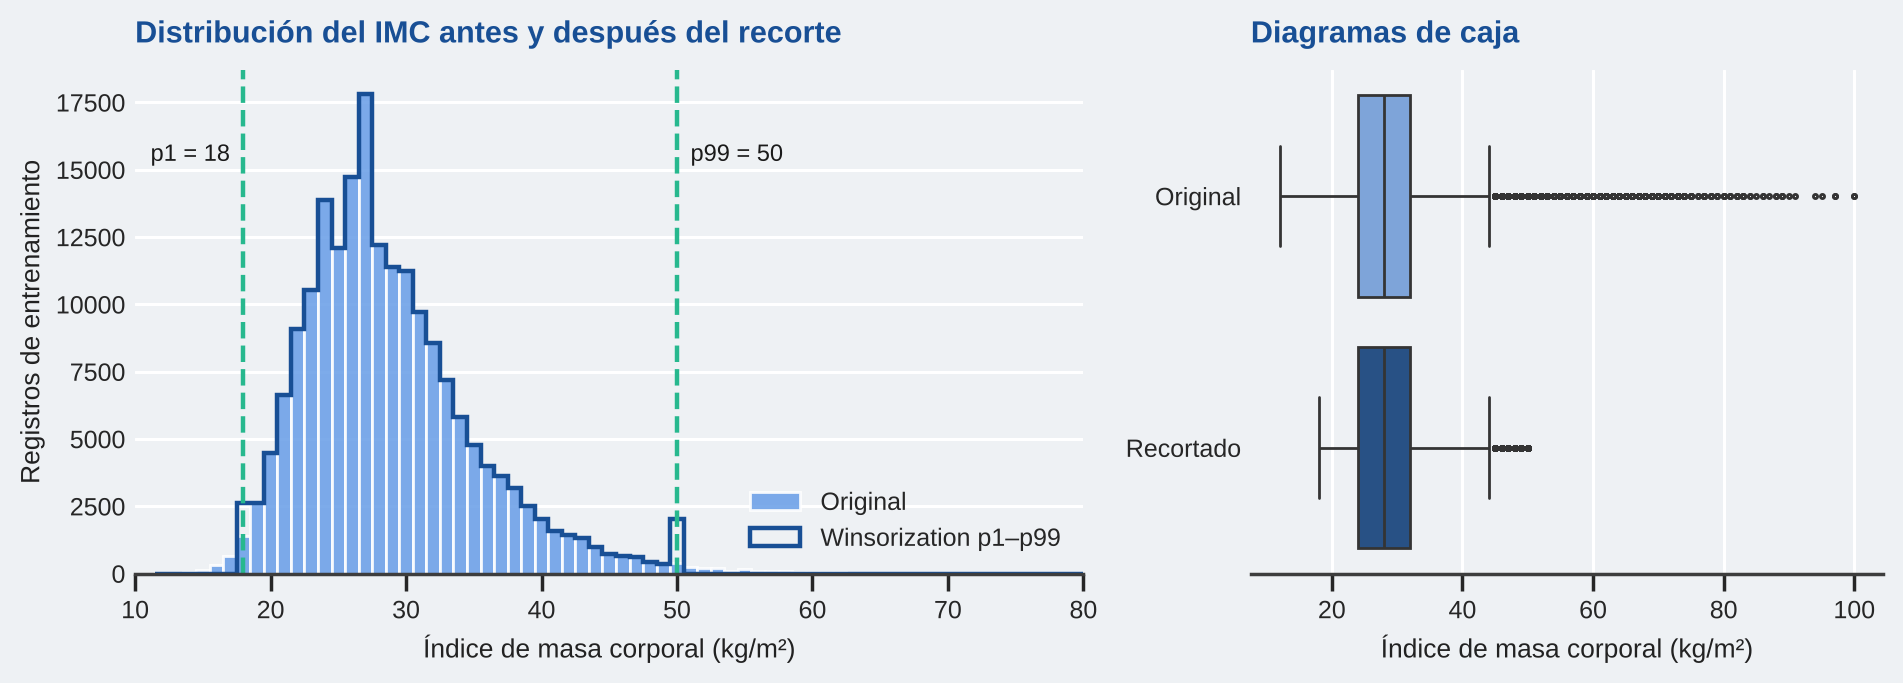

In [7]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(9.6, 3.5), gridspec_kw={"width_ratios": [1.5, 1]})
bins = np.arange(11.5, 101.5, 1)
a1.hist(b, bins=bins, color=CELESTE, alpha=.9, label="Original")
a1.hist(b_w, bins=bins, histtype="step", color=AZUL, lw=1.6, label="Winsorization p1–p99")
for v in (lo, hi): a1.axvline(v, color=MENTA, lw=1.6, ls="--")
a1.text(hi + 1, a1.get_ylim()[1]*.82, f"p99 = {hi:.0f}", fontsize=8.5, color=TINTA); a1.text(lo - 1, a1.get_ylim()[1]*.82, f"p1 = {lo:.0f}", fontsize=8.5, color=TINTA, ha="right")
a1.set(xlabel="Índice de masa corporal (kg/m²)", ylabel="Registros de entrenamiento", xlim=(10, 80), title="Distribución del IMC antes y después del recorte"); a1.legend()
sns.boxplot(data=pd.DataFrame({"Original": b, "Recortado": b_w}), orient="h", palette=[CELESTE, AZUL], fliersize=1.5, linewidth=1, ax=a2)
a2.set(xlabel="Índice de masa corporal (kg/m²)", title="Diagramas de caja"); a2.grid(axis="x", color="white"); a2.grid(axis="y", visible=False)
fig.tight_layout(); fig.savefig(FIG / "fig2_winsorizacion.png"); plt.show()

**Decisión: winsorization en los percentiles 1 y 99, ajustada con entrenamiento.** Los valores altos de IMC son casos reales de obesidad severa y tienen una prevalencia de diabetes muy superior al resto, de modo que eliminarlos descartaría justamente a la población de mayor interés. El recorte conserva todos los registros, reduce la asimetría y la curtosis, y limita la influencia de valores poco plausibles (por encima de 70) sobre los modelos lineales y el escalamiento. La transformación logarítmica también reduce la asimetría, pero dificulta la interpretación de coeficientes y del IMC como variable objetivo de regresión, así que se reserva como alternativa para la Fase 3.

## 5. Experimento de imputación bajo MCAR, MAR y MNAR
Como el archivo no tiene faltantes, la elección del imputador se fundamenta con un experimento controlado: sobre una muestra de entrenamiento se oculta el 10 % del IMC bajo cada mecanismo y se comparan cuatro imputadores por su error al recuperar el valor real.
- **MCAR:** la probabilidad de ausencia es igual para todos.
- **MAR:** depende de variables observadas (más ausencia con menor ingreso y peor salud percibida).
- **MNAR:** depende del propio IMC (más ausencia cuanto mayor es el IMC), como ocurre con el subregistro de peso.

In [8]:
rng = np.random.default_rng(RANDOM_STATE)
muestra = win.transform(X_train).sample(20_000, random_state=RANDOM_STATE).reset_index(drop=True).astype(float)
def mascara(mecanismo, tasa=0.10):
    if mecanismo == "MCAR": p = np.full(len(muestra), tasa)
    elif mecanismo == "MAR": z = (8 - muestra.Income) / 7 + (muestra.GenHlth - 1) / 4; p = tasa * z / z.mean()
    else: z = np.exp((muestra.BMI - muestra.BMI.mean()) / muestra.BMI.std()); p = tasa * z / z.mean()
    return rng.random(len(muestra)) < np.clip(p, 0, 1)
imputadores = {"Media": lambda: SimpleImputer(strategy="mean"), "Mediana": lambda: SimpleImputer(strategy="median"),
               "KNNImputer (k = 5)": lambda: Pipeline([("esc", StandardScaler()), ("knn", KNNImputer(n_neighbors=5))]),
               "IterativeImputer": lambda: IterativeImputer(random_state=RANDOM_STATE, max_iter=10)}
filas = []
for mec in ["MCAR", "MAR", "MNAR"]:
    m = mascara(mec); Xm = muestra.copy(); Xm.loc[m, "BMI"] = np.nan; real = muestra.loc[m, "BMI"].values
    for nombre, f in imputadores.items():
        imp = f(); Z = imp.fit_transform(Xm); j = list(Xm.columns).index("BMI"); pred = Z[m, j]
        if "KNN" in nombre: pred = pred * imp.named_steps["esc"].scale_[j] + imp.named_steps["esc"].mean_[j]
        filas.append({"Mecanismo": mec, "Imputador": nombre, "RMSE": float(np.sqrt(np.mean((pred - real)**2))),
                      "Sesgo": float(np.mean(pred - real)), "% oculto": float(100*m.mean())})
imp_df = pd.DataFrame(filas); RES["imputacion"] = filas
tabla_imp = imp_df.pivot(index="Imputador", columns="Mecanismo", values="RMSE")[["MCAR", "MAR", "MNAR"]].loc[list(imputadores)]
sesgo_imp = imp_df.pivot(index="Imputador", columns="Mecanismo", values="Sesgo")[["MCAR", "MAR", "MNAR"]].loc[list(imputadores)]
display(tabla_imp.round(3)); display(sesgo_imp.round(3))

Mecanismo,MCAR,MAR,MNAR
Imputador,,,
Media,6.321,6.812,12.595
Mediana,6.341,7.178,13.220
KNNImputer (k = 5),6.415,6.819,11.750
IterativeImputer,5.909,6.362,11.727


Mecanismo,MCAR,MAR,MNAR
Imputador,,,
Media,0.196,-0.746,-9.492
Mediana,-0.533,-2.384,-10.306
KNNImputer (k = 5),0.264,-0.094,-8.458
IterativeImputer,0.197,-0.223,-8.741


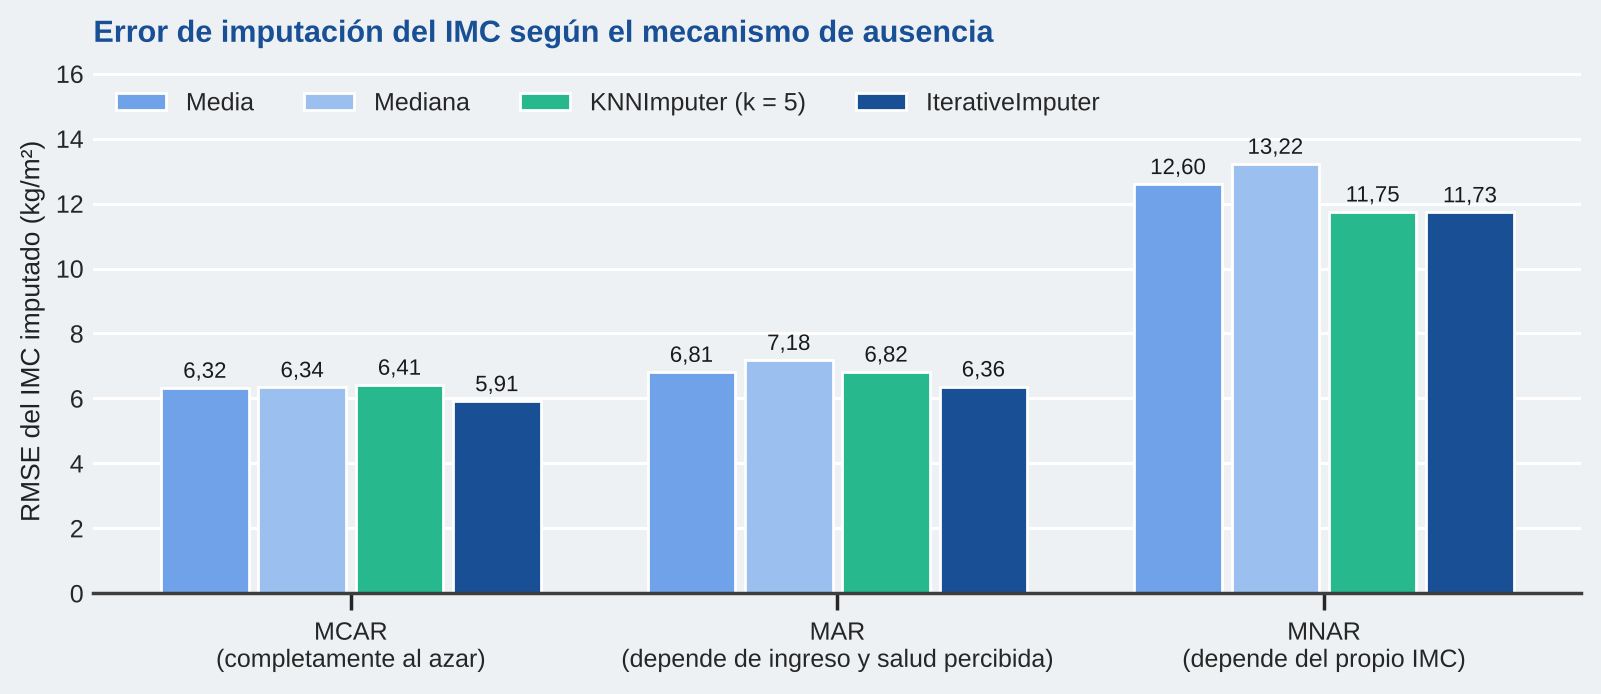

In [9]:
fig, ax = plt.subplots(figsize=(9.6, 3.4))
x = np.arange(3); w = .2; cols = [CELESTE, "#9bbfee", MENTA, AZUL]
for k, (nombre, col) in enumerate(zip(imputadores, cols)):
    v = tabla_imp.loc[nombre].values; br = ax.bar(x + (k - 1.5) * w, v, w - .02, color=col, label=nombre)
    ax.bar_label(br, labels=[es(t, 2) for t in v], fontsize=8, color=TINTA, padding=2)
ax.set_xticks(x, ["MCAR\n(completamente al azar)", "MAR\n(depende de ingreso y salud percibida)", "MNAR\n(depende del propio IMC)"])
ax.set(ylabel="RMSE del IMC imputado (kg/m²)", title="Error de imputación del IMC según el mecanismo de ausencia", ylim=(0, tabla_imp.values.max()*1.22))
ax.legend(ncol=4, loc="upper left"); fig.savefig(FIG / "fig1_imputacion.png"); plt.show()

**Lectura y decisión.**
- `IterativeImputer` obtiene el menor error en los tres mecanismos (entre 6 % y 7 % menos que la media bajo MCAR y MAR). `KNNImputer` no mejora a la media bajo MCAR ni bajo MAR.
- La mediana tiene el mayor sesgo porque el IMC es asimétrico (mediana menor que la media).
- **Ningún imputador corrige el mecanismo MNAR:** todos subestiman el IMC en más de 8 kg/m² cuando la ausencia depende del propio valor. Si los faltantes originales del BRFSS eran de este tipo, ninguna imputación los habría recuperado sin sesgo.
- Para el pipeline se adopta `SimpleImputer` con **mediana** en las variables numéricas y **moda** en las binarias y ordinales. Razones: devuelven siempre un valor que existe en la escala (la media produciría, por ejemplo, 4,2 días o un grupo de edad 7,9), son robustas a valores extremos, su costo es despreciable y hoy no hay faltantes reales, de modo que el paso actúa solo como salvaguarda para el tablero de la Fase 4. Si en producción aparecieran faltantes frecuentes en el IMC, el experimento indica que debe migrarse a `IterativeImputer`.

## 6. Ingeniería de variables
Se crean cuatro variables derivadas con respaldo en el dominio. Todas son transformaciones fila a fila con umbrales fijos de la literatura (no usan estadísticos de los datos), por lo que no pueden producir fuga de información.

| Variable | Definición | Respaldo |
|---|---|---|
| `BMI_cat` | Categoría del IMC: bajo peso (< 18,5), normal (18,5–24,9), sobrepeso (25–29,9), obesidad I (30–34,9), II (35–39,9) y III (≥ 40) | Clasificación de la OMS (2000) |
| `CardioRisk` | Número de condiciones cardiometabólicas: `HighBP` + `HighChol` + `HeartDiseaseorAttack` + `Stroke` (0 a 4) | Agregación de comorbilidades asociadas a la diabetes tipo 2 |
| `UnhealthyDays` | Días no saludables: mín(30, `MentHlth` + `PhysHlth`) | Medida «Healthy Days» del CDC (2000) |
| `Age_BMI` | Interacción grupo de edad × IMC recortado | Hallazgo del EDA de la Fase 1 (Figura 6) |

In [10]:
CAT_IMC = ["Bajo peso", "Normal", "Sobrepeso", "Obesidad I", "Obesidad II", "Obesidad III"]
def crear_variables(X):
    # Variables derivadas del dominio. Se aplica después del recorte del IMC.
    X = X.copy()
    X["BMI_cat"] = pd.cut(X["BMI"], bins=[-np.inf, 18.5, 25, 30, 35, 40, np.inf], right=False, labels=CAT_IMC).astype(str)
    X["CardioRisk"] = X["HighBP"] + X["HighChol"] + X["HeartDiseaseorAttack"] + X["Stroke"]
    X["UnhealthyDays"] = np.minimum(30, X["MentHlth"] + X["PhysHlth"])
    X["Age_BMI"] = X["Age"] * X["BMI"]
    return X

Xtr_fe = crear_variables(win.transform(X_train))
der = Xtr_fe.assign(y=y_train.values)
prev_cat = der.groupby("BMI_cat")["y"].agg(["mean", "size"]).loc[CAT_IMC]
prev_cr = der.groupby("CardioRisk")["y"].agg(["mean", "size"])
der["ud_g"] = pd.cut(der.UnhealthyDays, [-1, 0, 5, 13, 29, 30], labels=["0", "1–5", "6–13", "14–29", "30"])
prev_ud = der.groupby("ud_g", observed=True)["y"].agg(["mean", "size"])
asoc = {"BMI_cat (ordinal)": stats.spearmanr(der.BMI_cat.map({c: i for i, c in enumerate(CAT_IMC)}), der.y)[0],
        "CardioRisk": stats.spearmanr(der.CardioRisk, der.y)[0], "UnhealthyDays": stats.spearmanr(der.UnhealthyDays, der.y)[0],
        "Age_BMI": stats.spearmanr(der.Age_BMI, der.y)[0], "BMI (referencia)": stats.spearmanr(der.BMI, der.y)[0],
        "Age (referencia)": stats.spearmanr(der.Age, der.y)[0], "HighBP (referencia)": stats.spearmanr(der.HighBP, der.y)[0]}
chi_cat = stats.chi2_contingency(pd.crosstab(der.BMI_cat, der.y)); chi_cr = stats.chi2_contingency(pd.crosstab(der.CardioRisk, der.y))
RES["derivadas"] = {"prev_cat": {k: [float(v["mean"]), int(v["size"])] for k, v in prev_cat.iterrows()},
    "prev_cr": {int(k): [float(v["mean"]), int(v["size"])] for k, v in prev_cr.iterrows()},
    "prev_ud": {str(k): [float(v["mean"]), int(v["size"])] for k, v in prev_ud.iterrows()},
    "spearman": {k: float(v) for k, v in asoc.items()}, "chi_cat": float(chi_cat[0]), "chi_cr": float(chi_cr[0]),
    "ud_media": float(der.UnhealthyDays.mean()), "ud_cero": float(100*(der.UnhealthyDays == 0).mean())}
pd.Series(asoc, name="Correlación de Spearman con Diabetes_binary").round(3).to_frame()

,Correlación de Spearman con Diabetes_binary
BMI_cat (ordinal),0.188
CardioRisk,0.296
UnhealthyDays,0.083
Age_BMI,0.277
BMI (referencia),0.192
Age (referencia),0.189
HighBP (referencia),0.257


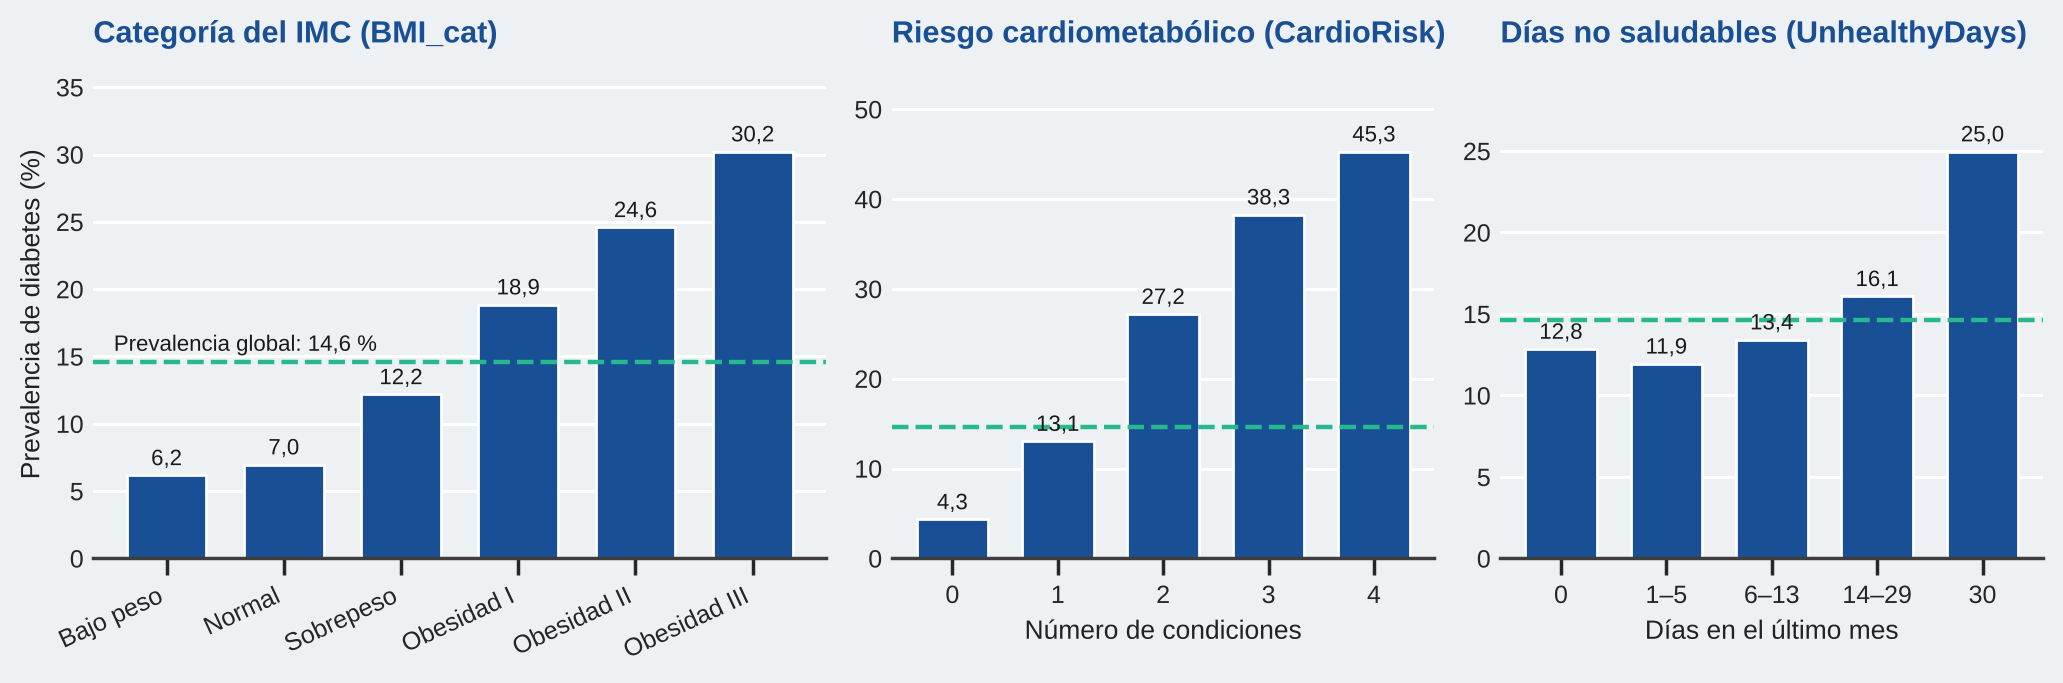

In [11]:
fig, axs = plt.subplots(1, 3, figsize=(10.4, 3.5), gridspec_kw={"width_ratios": [1.35, 1, 1]})
prev_global = 100 * y_train.mean()
for ax, pv, tit, xl, rot in [(axs[0], prev_cat, "Categoría del IMC (BMI_cat)", "", 25), (axs[1], prev_cr, "Riesgo cardiometabólico (CardioRisk)", "Número de condiciones", 0),
                             (axs[2], prev_ud, "Días no saludables (UnhealthyDays)", "Días en el último mes", 0)]:
    br = ax.bar([str(i) for i in pv.index], 100 * pv["mean"], color=AZUL, width=.68)
    ax.bar_label(br, labels=[es(v, 1) for v in 100 * pv["mean"]], fontsize=8, color=TINTA, padding=2)
    ax.axhline(prev_global, color=MENTA, lw=1.6, ls="--"); ax.set(title=tit, xlabel=xl, ylim=(0, 100 * pv["mean"].max() * 1.2))
    ax.tick_params(axis="x", rotation=rot); plt.setp(ax.get_xticklabels(), ha="right" if rot else "center")
axs[0].set_ylabel("Prevalencia de diabetes (%)"); axs[0].text(-.45, prev_global + .8, f"Prevalencia global: {es(prev_global, 1)} %", fontsize=8, color=TINTA)
fig.tight_layout(); fig.savefig(FIG / "fig3_derivadas.png"); plt.show()

**Lectura.**
- `BMI_cat` y `CardioRisk` ordenan a la población en un gradiente monótono de prevalencia de diabetes. `CardioRisk` alcanza una asociación con la variable objetivo (ρ = 0,30) superior a la de cualquiera de sus componentes por separado, y `Age_BMI` (ρ = 0,28) supera a la edad y al IMC individuales.
- `UnhealthyDays` tiene una asociación débil (ρ = 0,08) y no monótona: la prevalencia solo aumenta de forma clara en quienes reportan 14 días o más. Se conserva por su valor descriptivo para la segmentación.

**Controles derivados de este análisis.**
- **Colinealidad perfecta.** `CardioRisk` es la suma exacta de cuatro predictores que ya están en el modelo. En modelos lineales esto hace que los coeficientes individuales no sean identificables, así que **se excluye de los modelos base lineales** y se reserva para el clustering, los modelos basados en árboles y el tablero.
- **Fuga de la variable objetivo en regresión.** `BMI_cat` y `Age_BMI` se calculan a partir del IMC, de modo que **se excluyen del modelo de regresión del IMC**; usarlas equivaldría a entregar la respuesta al modelo.

## 7. Codificación y escalamiento dentro de un `Pipeline`
- **Ordinal Encoding** para `GenHlth`, `Age`, `Education` e `Income`: sus categorías tienen orden natural y el archivo ya las trae como enteros ordenados; se declaran las categorías válidas para detectar códigos desconocidos.
- **One-Hot Encoding** para `BMI_cat` (seis categorías), con `drop="first"` para evitar la colinealidad perfecta y `handle_unknown="ignore"`. Permite un efecto no lineal del IMC en modelos lineales.
- **Variables binarias:** ya están en 0/1 y no requieren codificación.
- **Target Encoding** no se utiliza: ninguna variable tiene alta cardinalidad y es la codificación con mayor riesgo de fuga.
- **StandardScaler** para las variables numéricas y ordinales. `RobustScaler` no es adecuado para `MentHlth` y `PhysHlth` porque su rango intercuartílico es cero, y `MinMaxScaler` sería sensible a los extremos.

Todos los pasos (recorte, variables derivadas, imputación, codificación y escalamiento) quedan encadenados en un único `Pipeline`. Sus parámetros se aprenden solo con los datos con que se llama `fit` (entrenamiento, o los pliegues de entrenamiento en validación cruzada).

In [12]:
BIN = ["HighBP", "HighChol", "CholCheck", "Smoker", "Stroke", "HeartDiseaseorAttack", "PhysActivity", "NoDocbcCost", "DiffWalk", "Sex"]
ORD = ["GenHlth", "Age", "Education", "Income"]
ORD_CATS = [list(range(1, 6)), list(range(1, 14)), list(range(1, 7)), list(range(1, 12))]
NUM_CLF = ["BMI", "MentHlth", "PhysHlth", "UnhealthyDays", "Age_BMI"]     # CardioRisk se excluye de los modelos lineales (colinealidad perfecta)
NUM_ORIG = ["BMI", "MentHlth", "PhysHlth"]

def preprocesador(num, bin_, ord_=ORD, cat=("BMI_cat",)):
    pasos = [("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("esc", StandardScaler())]), list(num)),
             ("ord", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                               ("cod", OrdinalEncoder(categories=[ORD_CATS[ORD.index(c)] for c in ord_], handle_unknown="use_encoded_value", unknown_value=-1)),
                               ("esc", StandardScaler())]), list(ord_)),
             ("bin", SimpleImputer(strategy="most_frequent"), list(bin_))]
    if cat: pasos.append(("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                                           ("ohe", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False))]), list(cat)))
    return ColumnTransformer(pasos, remainder="drop", verbose_feature_names_out=False)

def pipeline_clf(modelo, derivadas=True, muestreo=None):
    pasos = [("recorte", Winsorizer())]
    if derivadas: pasos += [("derivadas", FunctionTransformer(crear_variables)), ("prep", preprocesador(NUM_CLF, BIN))]
    else: pasos += [("prep", preprocesador(NUM_ORIG, BIN, cat=()))]
    if muestreo is not None: pasos.append(("muestreo", muestreo))
    pasos.append(("modelo", modelo))
    return ImbPipeline(pasos)

demo = pipeline_clf(LogisticRegression(max_iter=1000)).fit(X_train, y_train)
prep = demo.named_steps["prep"]; nombres = list(prep.get_feature_names_out())
Zt = prep.transform(crear_variables(demo.named_steps["recorte"].transform(X_train)))
Zv = prep.transform(crear_variables(demo.named_steps["recorte"].transform(X_val)))
esc = pd.DataFrame({"Media en train": Zt[:, :9].mean(0), "Desv. en train": Zt[:, :9].std(0), "Media en validación": Zv[:, :9].mean(0),
                    "Desv. en validación": Zv[:, :9].std(0)}, index=nombres[:9])
RES["prep"] = {"n_features": len(nombres), "nombres": nombres, "escala": esc.reset_index(names="Variable").to_dict("records")}
print(f"Variables de entrada al modelo de clasificación: {len(nombres)}"); print(nombres)
esc.round(3)

Variables de entrada al modelo de clasificación: 24
['BMI', 'MentHlth', 'PhysHlth', 'UnhealthyDays', 'Age_BMI', 'GenHlth', 'Age', 'Education', 'Income', 'HighBP', 'HighChol', 'CholCheck', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'NoDocbcCost', 'DiffWalk', 'Sex', 'BMI_cat_Normal', 'BMI_cat_Obesidad I', 'BMI_cat_Obesidad II', 'BMI_cat_Obesidad III', 'BMI_cat_Sobrepeso']


,Media en train,Desv. en train,Media en validación,Desv. en validación
BMI,0.0,1.0,0.005,1.004
MentHlth,0.0,1.0,-0.002,0.995
PhysHlth,0.0,1.0,-0.003,0.998
UnhealthyDays,0.0,1.0,-0.000,1.000
Age_BMI,-0.0,1.0,-0.005,1.000
GenHlth,-0.0,1.0,0.001,0.997
Age,0.0,1.0,-0.007,1.002
Education,-0.0,1.0,0.002,0.998
Income,0.0,1.0,0.004,0.997


**Comprobación de ausencia de fuga.** En entrenamiento las variables escaladas tienen media 0 y desviación 1 exactas; en validación los valores son cercanos pero no idénticos. Esa diferencia es la evidencia de que el escalador **no** vio los datos de validación.

## 8. Tratamiento del desbalance de clases
La clase positiva representa el 14,6 % (razón 5,8 a 1). Se comparan cuatro estrategias con la misma regresión logística, ajustadas con entrenamiento y evaluadas en validación. El remuestreo (`SMOTE`, submuestreo) se aplica dentro de un `Pipeline` de *imbalanced-learn*, que lo ejecuta solo durante `fit` y nunca sobre validación o prueba.

In [13]:
def metricas_clf(y, proba, umbral=0.5):
    pred = (proba >= umbral).astype(int)
    return {"Accuracy": accuracy_score(y, pred), "Balanced accuracy": balanced_accuracy_score(y, pred),
            "Precision": precision_score(y, pred, zero_division=0), "Recall": recall_score(y, pred), "F1 (clase 1)": f1_score(y, pred, zero_division=0),
            "F1 macro": f1_score(y, pred, average="macro", zero_division=0), "F1 ponderado": f1_score(y, pred, average="weighted", zero_division=0),
            "AUC-ROC": roc_auc_score(y, proba), "AUC-PR": average_precision_score(y, proba)}
LR = lambda **k: LogisticRegression(max_iter=1000, random_state=RANDOM_STATE, **k)
estrategias = {"Sin tratamiento": pipeline_clf(LR()),
               "class_weight = balanced": pipeline_clf(LR(class_weight="balanced")),
               "SMOTE": pipeline_clf(LR(), muestreo=SMOTE(random_state=RANDOM_STATE)),
               "Submuestreo aleatorio": pipeline_clf(LR(), muestreo=RandomUnderSampler(random_state=RANDOM_STATE))}
filas, modelos_imb = [], {}
for nombre, p in estrategias.items():
    p.fit(X_train, y_train); modelos_imb[nombre] = p
    filas.append({"Estrategia": nombre, **metricas_clf(y_val, p.predict_proba(X_val)[:, 1])})
# Alternativa sin remuestreo: mover el umbral de decisión (elegido en entrenamiento, evaluado en validación)
p0 = modelos_imb["Sin tratamiento"]; pr_tr = p0.predict_proba(X_train)[:, 1]
prec, rec, thr = precision_recall_curve(y_train, pr_tr); f1s = 2 * prec * rec / (prec + rec + 1e-12); umbral_opt = float(thr[np.argmax(f1s[:-1])])
filas.append({"Estrategia": f"Umbral ajustado ({umbral_opt:.2f})", **metricas_clf(y_val, p0.predict_proba(X_val)[:, 1], umbral_opt)})
imb = pd.DataFrame(filas).set_index("Estrategia"); RES["desbalance"] = imb.reset_index().to_dict("records"); RES["umbral_opt"] = umbral_opt
imb.round(3)

,Accuracy,Balanced accuracy,Precision,Recall,F1 (clase 1),F1 macro,F1 ponderado,AUC-ROC,AUC-PR
Estrategia,,,,,,,,,
Sin tratamiento,0.857,0.562,0.546,0.145,0.229,0.575,0.820,0.807,0.403
class_weight = balanced,0.718,0.732,0.309,0.751,0.438,0.625,0.757,0.807,0.402
SMOTE,0.718,0.732,0.309,0.751,0.438,0.625,0.757,0.805,0.397
Submuestreo aleatorio,0.718,0.732,0.309,0.752,0.438,0.625,0.757,0.807,0.402
Umbral ajustado (0.22),0.787,0.707,0.361,0.594,0.449,0.659,0.807,0.807,0.403


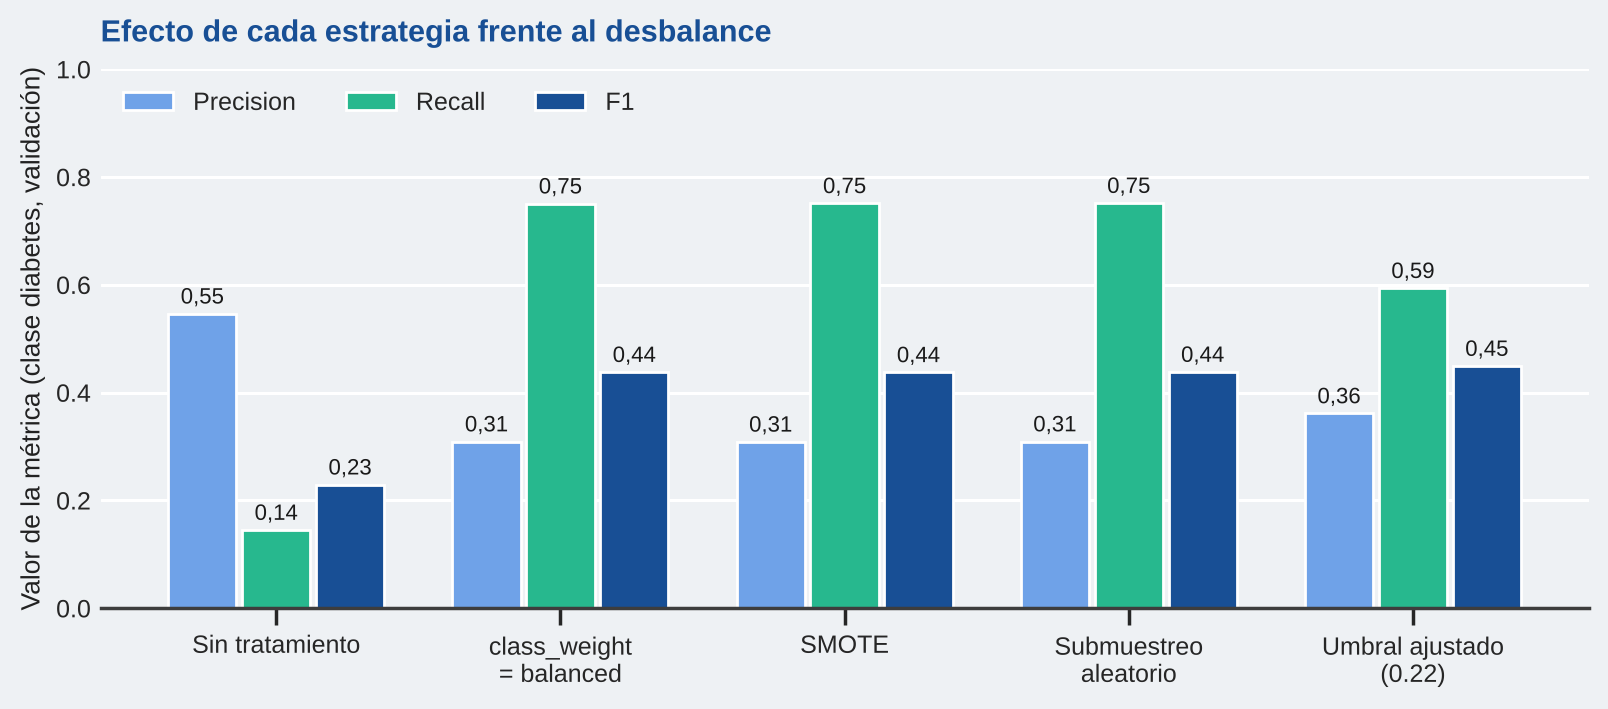

In [14]:
fig, ax = plt.subplots(figsize=(9.6, 3.5))
x = np.arange(len(imb)); w = .26
for k, (m, col) in enumerate([("Precision", CELESTE), ("Recall", MENTA), ("F1 (clase 1)", AZUL)]):
    br = ax.bar(x + (k - 1) * w, imb[m], w - .02, color=col, label=m.replace(" (clase 1)", "")); ax.bar_label(br, labels=[es(v, 2) for v in imb[m]], fontsize=8, color=TINTA, padding=2)
ax.set_xticks(x, [s.replace(" = ", "\n= ").replace("Submuestreo ", "Submuestreo\n").replace("Umbral ajustado ", "Umbral ajustado\n") for s in imb.index])
ax.set(ylabel="Valor de la métrica (clase diabetes, validación)", ylim=(0, 1), title="Efecto de cada estrategia frente al desbalance"); ax.legend(ncol=3, loc="upper left")
fig.savefig(FIG / "fig4_desbalance.png"); plt.show()

**Decisión: `class_weight="balanced"`.** Sin tratamiento el modelo detecta solo el 14 % de los diabéticos. Las tres técnicas de reequilibrio producen resultados prácticamente idénticos (recall ≈ 0,75; F1 ≈ 0,44) y no alteran el AUC-ROC, porque cambian el punto de operación y no la capacidad de ordenar los casos. Se adopta el ajuste de pesos porque: (a) no crea registros sintéticos; (b) `SMOTE` interpola entre vecinos y genera valores fraccionarios en variables binarias y ordinales (por ejemplo, `HighBP` = 0,4), que no existen en la realidad, y exigiría la variante `SMOTENC`; (c) no descarta información, como sí hace el submuestreo; y (d) es la opción más económica en cómputo. Mover el umbral de decisión logra el F1 más alto (0,45) con menos falsos positivos, pero sacrifica recall (0,59); se conserva como herramienta para elegir el punto de operación en la Fase 3.

## 9. Modelo base de clasificación (diabetes)
Se establecen tres referencias: un clasificador trivial que siempre predice la clase mayoritaria, uno aleatorio estratificado y la regresión logística básica con pesos balanceados. Se reporta el desempeño en entrenamiento y validación (para detectar sobreajuste) y una validación cruzada estratificada de 5 pliegues sobre entrenamiento.

In [15]:
base = {"Dummy (clase mayoritaria)": pipeline_clf(DummyClassifier(strategy="most_frequent")),
        "Dummy (estratificado)": pipeline_clf(DummyClassifier(strategy="stratified", random_state=RANDOM_STATE)),
        "Regresión logística (baseline)": modelos_imb["class_weight = balanced"]}
filas = []
for nombre, p in base.items():
    p.fit(X_train, y_train)
    for conj, X_, y_ in [("Entrenamiento", X_train, y_train), ("Validación", X_val, y_val)]:
        filas.append({"Modelo": nombre, "Conjunto": conj, **metricas_clf(y_, p.predict_proba(X_)[:, 1])})
base_df = pd.DataFrame(filas); RES["baseline_clf"] = filas
cv = cross_validate(pipeline_clf(LR(class_weight="balanced")), X_train, y_train, cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE),
                    scoring={"f1": "f1", "recall": "recall", "precision": "precision", "roc_auc": "roc_auc", "pr_auc": "average_precision"}, n_jobs=-1)
RES["cv_clf"] = {k.replace("test_", ""): [float(v.mean()), float(v.std())] for k, v in cv.items() if k.startswith("test_")}
print("Validación cruzada (5 pliegues, entrenamiento):", {k: f"{m:.3f} ± {s:.3f}" for k, (m, s) in RES["cv_clf"].items()})
base_df.set_index(["Modelo", "Conjunto"]).round(3)

Validación cruzada (5 pliegues, entrenamiento): {'f1': '0.441 ± 0.002', 'recall': '0.756 ± 0.004', 'precision': '0.311 ± 0.001', 'roc_auc': '0.810 ± 0.003', 'pr_auc': '0.402 ± 0.007'}


Accuracy  Balanced accuracy  \
Modelo                         Conjunto                                     
Dummy (clase mayoritaria)      Entrenamiento     0.854              0.500   
                               Validación        0.854              0.500   
Dummy (estratificado)          Entrenamiento     0.750              0.500   
                               Validación        0.752              0.502   
Regresión logística (baseline) Entrenamiento     0.720              0.735   
                               Validación        0.718              0.732   

                                              Precision  Recall  F1 (clase 1)  \
Modelo                         Conjunto                                         
Dummy (clase mayoritaria)      Entrenamiento      0.000   0.000         0.000   
                               Validación         0.000   0.000         0.000   
Dummy (estratificado)          Entrenamiento      0.146   0.146         0.146   
                               Validación         0.149   0.148         0.149   
Regresión logística (baseline) Entrenamiento      0.311   0.756         0.441   
                               Validación         0.309   0.751         0.438   

                                              F1 macro  F1 ponderado  AUC-ROC  \
Modelo                         Conjunto                                         
Dummy (clase mayoritaria)      Entrenamiento     0.461         0.786    0.500   
                               Validación        0.461         0.786    0.500   
Dummy (estratificado)          Entrenamiento     0.500         0.750    0.500   
                               Validación        0.502         0.751    0.502   
Regresión logística (baseline) Entrenamiento     0.627         0.759    0.810   
                               Validación        0.625         0.757    0.807   

                                              AUC-PR  
Modelo                         Conjunto               
Dummy (clase mayoritaria)      Entrenamiento   0.146  
                               Validación      0.146  
Dummy (estratificado)          Entrenamiento   0.146  
                               Validación      0.147  
Regresión logística (baseline) Entrenamiento   0.402  
                               Validación      0.402

In [16]:
# Aporte de la ingeniería de variables y sensibilidad a los duplicados (misma regresión logística, validación)
p_orig = pipeline_clf(LR(class_weight="balanced"), derivadas=False).fit(X_train, y_train)
tr_dd = pd.concat([X_train, y_train], axis=1).drop_duplicates()
p_dd = pipeline_clf(LR(class_weight="balanced")).fit(tr_dd.drop(columns=[TARGET_CLF]), tr_dd[TARGET_CLF])
abl = pd.DataFrame([{"Variante": "Solo variables originales (17 predictores)", **metricas_clf(y_val, p_orig.predict_proba(X_val)[:, 1])},
                    {"Variante": f"Originales + derivadas ({RES['prep']['n_features']} tras codificar)", **metricas_clf(y_val, base["Regresión logística (baseline)"].predict_proba(X_val)[:, 1])},
                    {"Variante": "Con derivadas, entrenamiento sin duplicados", **metricas_clf(y_val, p_dd.predict_proba(X_val)[:, 1])}]).set_index("Variante")
RES["ablacion"] = abl.reset_index().to_dict("records"); RES["n_train_sin_dup"] = len(tr_dd)
abl[["Precision", "Recall", "F1 (clase 1)", "F1 macro", "AUC-ROC", "AUC-PR"]].round(4)

,Precision,Recall,F1 (clase 1),F1 macro,AUC-ROC,AUC-PR
Variante,,,,,,
Solo variables originales (17 predictores),0.3080,0.7529,0.4371,0.6239,0.8057,0.4004
Originales + derivadas (24 tras codificar),0.3091,0.7505,0.4379,0.6250,0.8071,0.4018
"Con derivadas, entrenamiento sin duplicados",0.3116,0.7459,0.4396,0.6274,0.8063,0.3996


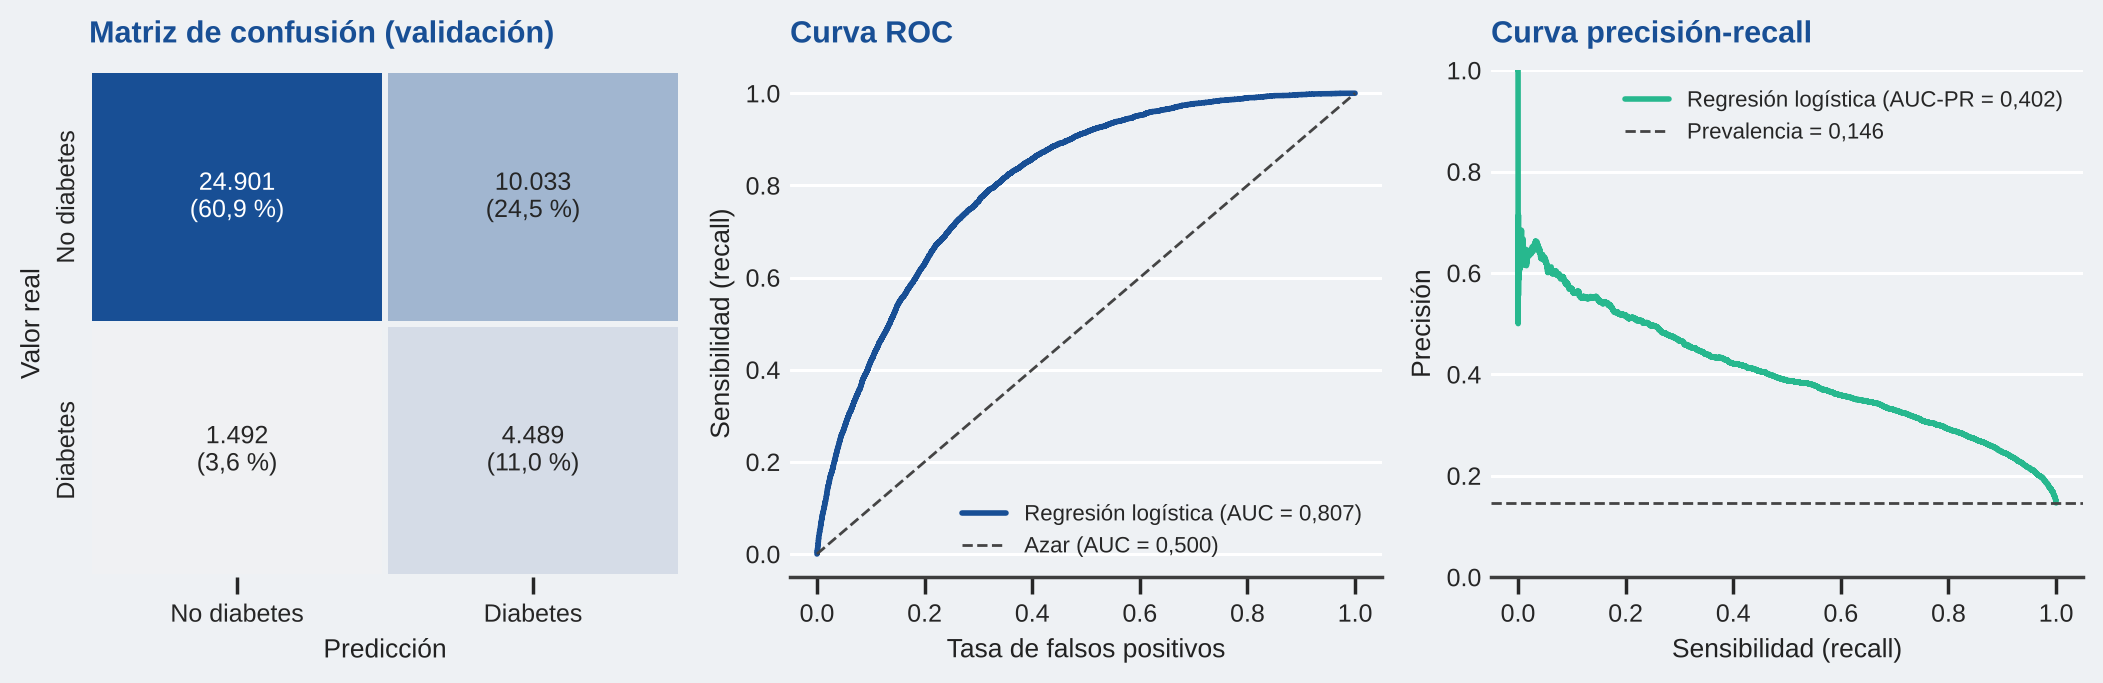

In [17]:
mb = base["Regresión logística (baseline)"]; pv = mb.predict_proba(X_val)[:, 1]; cm = confusion_matrix(y_val, (pv >= .5).astype(int))
RES["cm"] = cm.tolist()
fig, axs = plt.subplots(1, 3, figsize=(10.6, 3.5))
sns.heatmap(cm, annot=np.array([[f"{es(v)}\n({es(100*v/cm.sum(), 1)} %)" for v in r] for r in cm]), fmt="", cmap=sns.light_palette(AZUL, as_cmap=True), cbar=False,
            linewidths=2, linecolor=FONDO, xticklabels=["No diabetes", "Diabetes"], yticklabels=["No diabetes", "Diabetes"], annot_kws={"size": 9}, ax=axs[0])
axs[0].set(xlabel="Predicción", ylabel="Valor real", title="Matriz de confusión (validación)")
fpr, tpr, _ = roc_curve(y_val, pv); axs[1].plot(fpr, tpr, color=AZUL, lw=2, label=f"Regresión logística (AUC = {es(roc_auc_score(y_val, pv), 3)})")
axs[1].plot([0, 1], [0, 1], color=GRIS, ls="--", lw=1, label="Azar (AUC = 0,500)"); axs[1].set(xlabel="Tasa de falsos positivos", ylabel="Sensibilidad (recall)", title="Curva ROC"); axs[1].legend(loc="lower right", fontsize=8)
pr_, rc_, _ = precision_recall_curve(y_val, pv); axs[2].plot(rc_, pr_, color=MENTA, lw=2, label=f"Regresión logística (AUC-PR = {es(average_precision_score(y_val, pv), 3)})")
axs[2].axhline(y_val.mean(), color=GRIS, ls="--", lw=1, label=f"Prevalencia = {es(y_val.mean(), 3)}"); axs[2].set(xlabel="Sensibilidad (recall)", ylabel="Precisión", title="Curva precisión-recall", ylim=(0, 1)); axs[2].legend(loc="upper right", fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "fig5_baseline_clf.png"); plt.show()

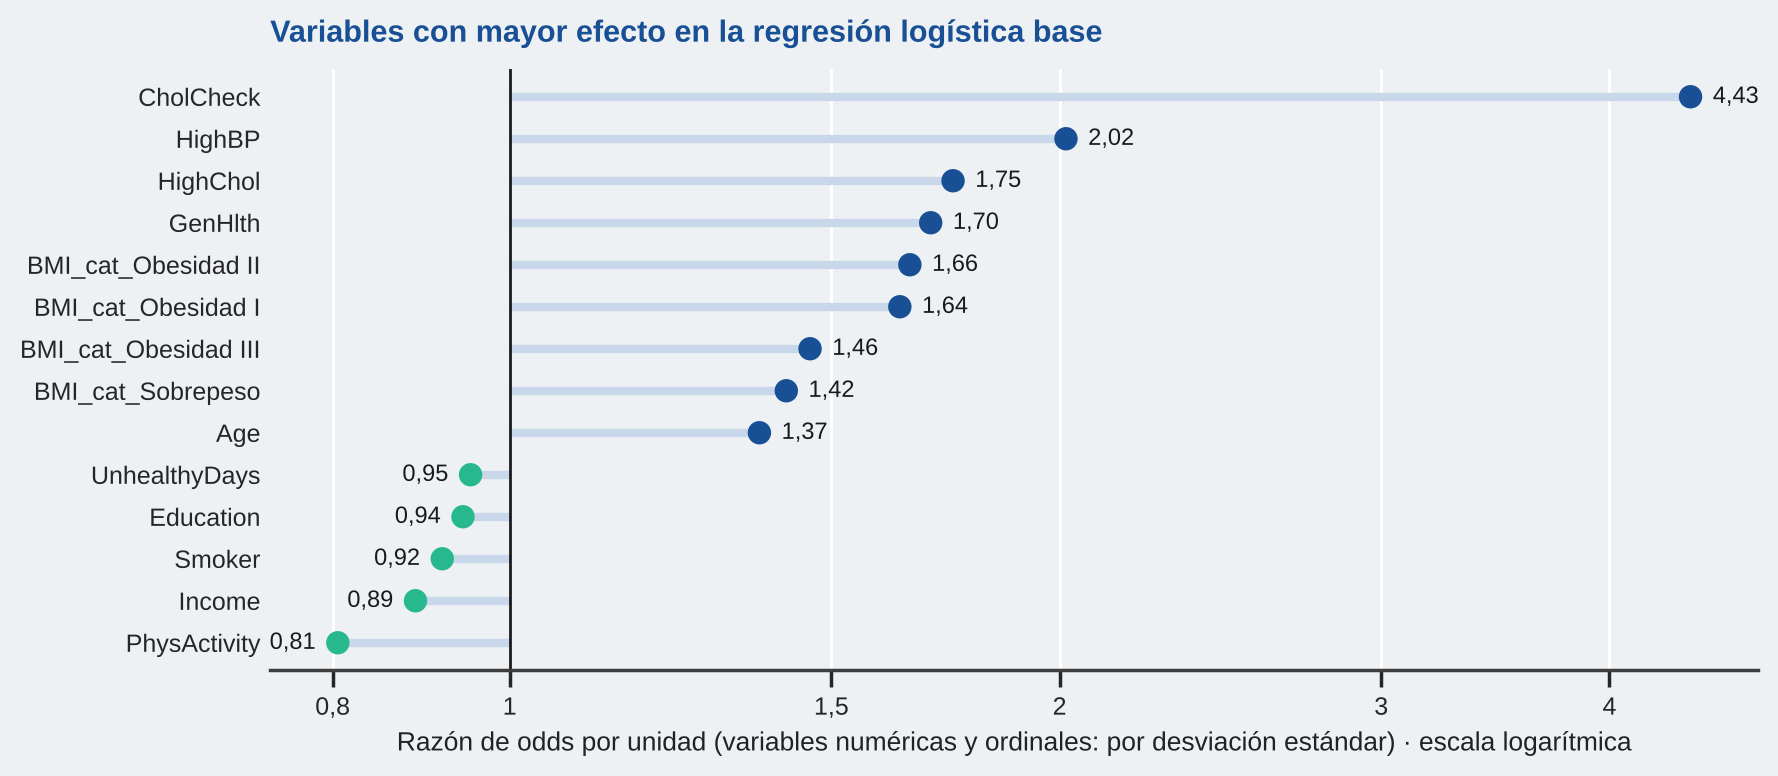

In [18]:
coef = pd.Series(mb.named_steps["modelo"].coef_[0], index=mb.named_steps["prep"].get_feature_names_out())
orr = np.exp(coef).sort_values(); top = pd.concat([orr.head(5), orr.tail(9)])
RES["odds"] = {k: float(v) for k, v in orr.items()}
fig, ax = plt.subplots(figsize=(9.6, 3.9))
ax.hlines(range(len(top)), 1, top.values, color="#c9d7ea", lw=3); ax.scatter(top.values, range(len(top)), color=[MENTA if v < 1 else AZUL for v in top.values], s=55, zorder=3)
for i, v in enumerate(top.values): ax.annotate(es(v, 2), (v, i), xytext=(8 if v >= 1 else -8, 0), textcoords="offset points", va="center", ha="left" if v >= 1 else "right", fontsize=8.5, color=TINTA)
ax.axvline(1, color=TINTA, lw=1); ax.set_yticks(range(len(top)), top.index); ax.set_xscale("log"); ax.set_xticks([.8, 1, 1.5, 2, 3, 4], ["0,8", "1", "1,5", "2", "3", "4"]); ax.minorticks_off(); ax.grid(axis="y", visible=False); ax.grid(axis="x", color="white")
ax.set(xlabel="Razón de odds por unidad (variables numéricas y ordinales: por desviación estándar) · escala logarítmica", title="Variables con mayor efecto en la regresión logística base")
fig.savefig(FIG / "fig6_odds.png"); plt.show()

**Lectura del baseline de clasificación.**
- El clasificador trivial alcanza una exactitud alta sin detectar un solo diabético: la exactitud no sirve como métrica en este problema.
- La regresión logística básica fija el **umbral mínimo** que deben superar los modelos de la Fase 3 (valores en la tabla anterior).
- Las métricas de entrenamiento y validación son prácticamente iguales y la validación cruzada tiene una desviación mínima: **no hay sobreajuste** y la estimación es estable.
- La precisión es baja porque, con una prevalencia del 14,6 %, detectar tres de cada cuatro diabéticos implica muchos falsos positivos. En un tamizaje poblacional ese costo es aceptable frente al de no detectar un caso.
- **Aporte de las variables derivadas.** En este modelo lineal la mejora es marginal (el AUC-ROC pasa de 0,806 a 0,807). Su valor está en la interpretabilidad y se espera que sea mayor en los modelos no lineales y en la segmentación de la Fase 3.
- **Sensibilidad a los duplicados.** Entrenar sin los registros repetidos no cambia el resultado (diferencias en el tercer decimal), lo que respalda la decisión de conservarlos.
- **Lectura de los coeficientes.** Los mayores efectos corresponden a `CholCheck`, la hipertensión, el colesterol alto, la salud percibida, la obesidad y la edad. Este último refleja un sesgo de detección: quien se ha hecho chequeos tiene más probabilidad de haber sido diagnosticado; es una asociación, no una causa.
- **Advertencia sobre el objetivo de la Fase 1 (F1 ≥ 0,70).** El F1 de la clase positiva del baseline queda muy por debajo de 0,70, mientras que el F1 ponderado sí supera ese valor. La meta debe precisarse en la Fase 3 indicando a qué F1 se refiere.

## 10. Modelo base de regresión (IMC)
Variable objetivo: `BMI`. Predictores: las 16 variables restantes del archivo, incluida `Diabetes_binary`, más `UnhealthyDays`. Se excluyen `BMI_cat` y `Age_BMI` por derivarse de la variable objetivo, y `CardioRisk` por colinealidad perfecta con sus componentes. El modelo se entrena con el IMC recortado (p1–p99 de entrenamiento) y **se evalúa contra el IMC original**, sin recortar, para no favorecer artificialmente las métricas.

In [19]:
def variables_reg(X):
    X = X.copy(); X["UnhealthyDays"] = np.minimum(30, X["MentHlth"] + X["PhysHlth"]); return X
BIN_REG = BIN + ["Diabetes_binary"]; NUM_REG = ["MentHlth", "PhysHlth", "UnhealthyDays"]
def pipeline_reg(modelo, columnas=None):
    prep = preprocesador(NUM_REG, BIN_REG, cat=()) if columnas is None else ColumnTransformer(
        [("ord", Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("esc", StandardScaler())]), columnas)], remainder="drop")
    return Pipeline([("derivadas", FunctionTransformer(variables_reg)), ("prep", prep), ("modelo", modelo)])
Rtr, Rva = df.loc[X_train.index].drop(columns=["BMI"]), df.loc[X_val.index].drop(columns=["BMI"])
ytr_raw, yva_raw = df.loc[X_train.index, "BMI"].astype(float), df.loc[X_val.index, "BMI"].astype(float)
ytr_w = ytr_raw.clip(lo, hi)                                     # el recorte se aplica solo al objetivo de entrenamiento
mreg = lambda y, p: {"R²": r2_score(y, p), "RMSE": float(np.sqrt(mean_squared_error(y, p))), "MAE": mean_absolute_error(y, p)}
regs = {"Dummy (media)": pipeline_reg(DummyRegressor(strategy="mean")),
        "Regresión lineal simple (GenHlth)": pipeline_reg(LinearRegression(), columnas=["GenHlth"]),
        "Regresión lineal múltiple (baseline)": pipeline_reg(LinearRegression())}
filas = []
for nombre, p in regs.items():
    p.fit(Rtr, ytr_w)
    filas.append({"Modelo": nombre, "Conjunto": "Entrenamiento", **mreg(ytr_raw, p.predict(Rtr))}); filas.append({"Modelo": nombre, "Conjunto": "Validación", **mreg(yva_raw, p.predict(Rva))})
reg_df = pd.DataFrame(filas); RES["baseline_reg"] = filas
cvr = cross_validate(pipeline_reg(LinearRegression()), Rtr, ytr_w, cv=KFold(5, shuffle=True, random_state=RANDOM_STATE),
                     scoring={"r2": "r2", "rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error"}, n_jobs=-1)
RES["cv_reg"] = {"r2": [float(cvr["test_r2"].mean()), float(cvr["test_r2"].std())], "rmse": [float(-cvr["test_rmse"].mean()), float(cvr["test_rmse"].std())],
                 "mae": [float(-cvr["test_mae"].mean()), float(cvr["test_mae"].std())]}
mr = regs["Regresión lineal múltiple (baseline)"]; cr = pd.Series(mr.named_steps["modelo"].coef_, index=mr.named_steps["prep"].get_feature_names_out()).sort_values()
RES["coef_reg"] = {k: float(v) for k, v in cr.items()}; RES["reg_simple"] = {"pendiente_std": float(regs["Regresión lineal simple (GenHlth)"].named_steps["modelo"].coef_[0]),
    "intercepto": float(regs["Regresión lineal simple (GenHlth)"].named_steps["modelo"].intercept_), "r_genhlth": float(np.corrcoef(Rtr.GenHlth, ytr_w)[0, 1])}
print("Validación cruzada (5 pliegues):", {k: f"{m:.3f} ± {s:.3f}" for k, (m, s) in RES["cv_reg"].items()})
reg_df.set_index(["Modelo", "Conjunto"]).round(3)

Validación cruzada (5 pliegues): {'r2': '0.137 ± 0.002', 'rmse': '5.787 ± 0.018', 'mae': '4.440 ± 0.011'}


R²   RMSE    MAE
Modelo                               Conjunto                          
Dummy (media)                        Entrenamiento -0.000  6.520  4.884
                                     Validación    -0.000  6.570  4.913
Regresión lineal simple (GenHlth)    Entrenamiento  0.059  6.325  4.705
                                     Validación     0.059  6.373  4.730
Regresión lineal múltiple (baseline) Entrenamiento  0.133  6.070  4.512
                                     Validación     0.137  6.102  4.512

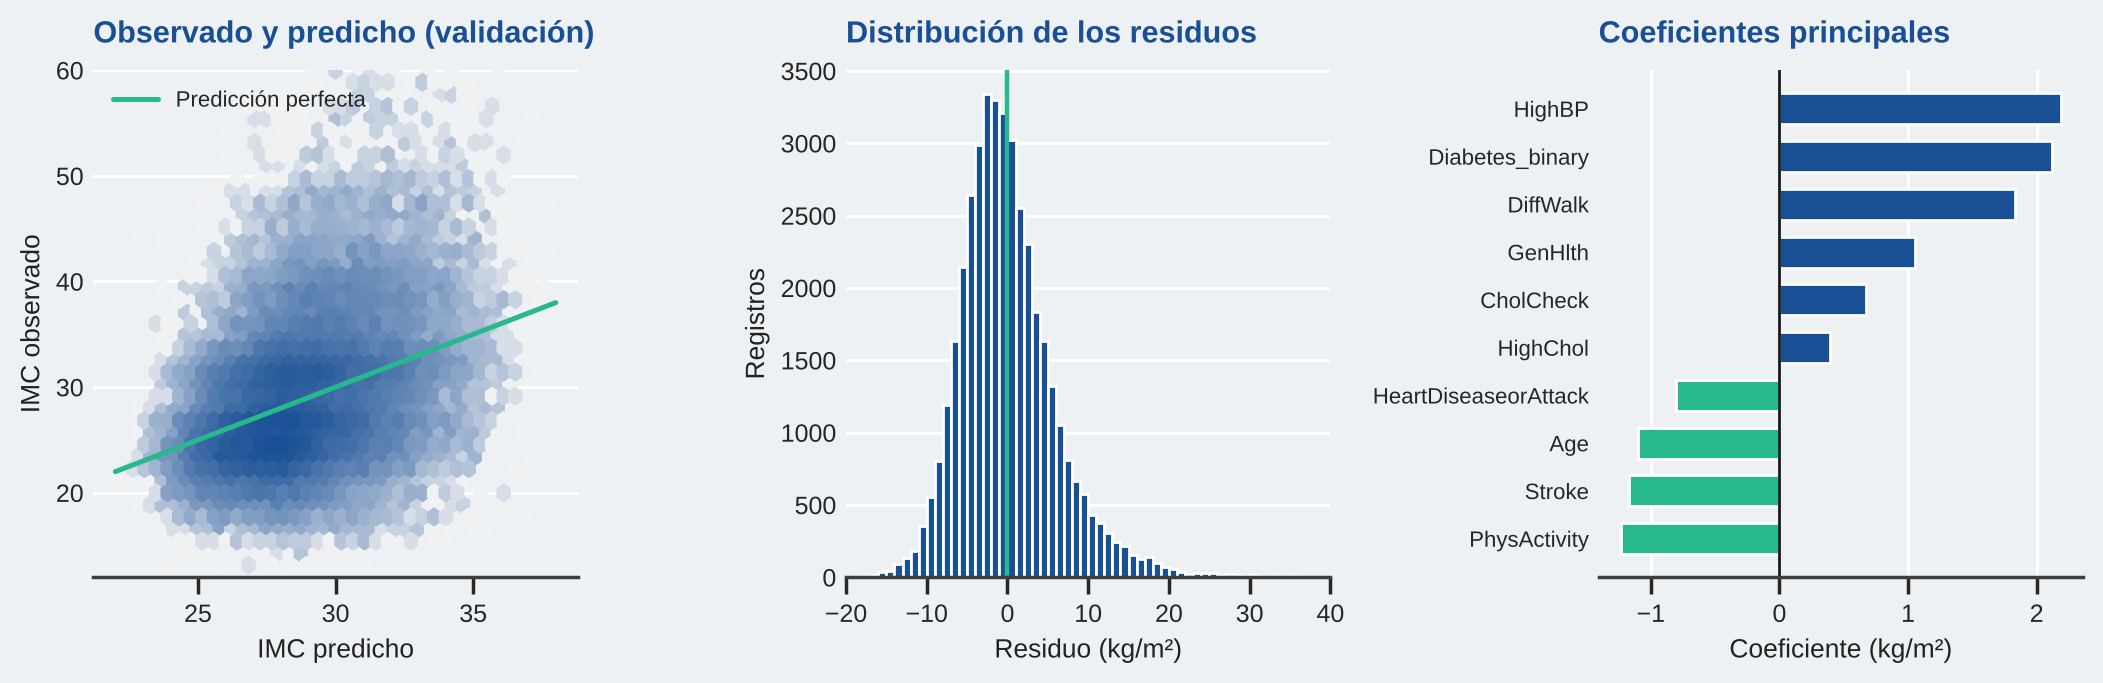

In [20]:
pred_v = mr.predict(Rva); resid = yva_raw - pred_v
RES["resid_reg"] = {"media": float(resid.mean()), "sd": float(resid.std()), "skew": float(stats.skew(resid)), "pred_min": float(pred_v.min()), "pred_max": float(pred_v.max())}
fig, axs = plt.subplots(1, 3, figsize=(10.6, 3.5))
hb = axs[0].hexbin(pred_v, yva_raw, gridsize=38, cmap=sns.light_palette(AZUL, as_cmap=True), mincnt=1, bins="log", extent=(22, 38, 12, 60))
axs[0].plot([22, 38], [22, 38], color=MENTA, lw=1.8, label="Predicción perfecta"); axs[0].set(xlabel="IMC predicho", ylabel="IMC observado", title="Observado y predicho (validación)", ylim=(12, 60)); axs[0].legend(loc="upper left", fontsize=8)
axs[1].hist(resid, bins=np.arange(-20, 41, 1), color=AZUL); axs[1].axvline(0, color=MENTA, lw=1.6); axs[1].set(xlabel="Residuo (kg/m²)", ylabel="Registros", title="Distribución de los residuos", xlim=(-20, 40))
top = pd.concat([cr.head(4), cr.tail(6)]); axs[2].barh(top.index, top.values, color=[MENTA if v < 0 else AZUL for v in top.values], height=.65)
axs[2].axvline(0, color=TINTA, lw=1); axs[2].grid(axis="y", visible=False); axs[2].grid(axis="x", color="white"); axs[2].set(xlabel="Coeficiente (kg/m²)", title="Coeficientes principales"); axs[2].tick_params(axis="y", labelsize=8)
fig.tight_layout(); fig.savefig(FIG / "fig7_baseline_reg.png"); plt.show()

**Lectura del baseline de regresión.**
- El modelo que predice siempre la media tiene R² = 0 por definición y fija el error de referencia.
- La regresión lineal simple con el mejor predictor individual (`GenHlth`) explica cerca del 6 % de la varianza; la regresión múltiple llega al 14 %, más del doble, pero sigue siendo baja. La validación cruzada se calcula sobre el IMC recortado y por eso su RMSE es algo menor que el de validación, medido contra el IMC original.
- Entrenamiento y validación coinciden: no hay sobreajuste; el problema es de **subajuste**. Las variables disponibles son conductuales y de salud percibida, y explican poco del IMC individual. Los residuos conservan la cola derecha del IMC.
- **Advertencia sobre el objetivo de la Fase 1 (R² ≥ 0,25).** Con este punto de partida, alcanzar 0,25 en la Fase 3 es exigente. Se evaluarán modelos no lineales (bosques aleatorios, potenciación del gradiente) y la transformación logarítmica del objetivo; si no se alcanza, la meta deberá reformularse con base en esta evidencia.

## 11. Exportación de artefactos y lista de chequeo

In [21]:
joblib.dump(base["Regresión logística (baseline)"], ART / "baseline_clasificacion.joblib")
joblib.dump(regs["Regresión lineal múltiple (baseline)"], ART / "baseline_regresion.joblib")
RES["versiones"] = {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__, "scikit-learn": sklearn.__version__,
                    "imbalanced-learn": imblearn.__version__, "matplotlib": mpl.__version__, "seaborn": sns.__version__}
json.dump(RES, open(ART / "resultados_fase2.json", "w", encoding="utf-8"), indent=1, ensure_ascii=False, default=float)
chk = pd.DataFrame({"Requisito de la guía (Fase 2)": [
    "Tratamiento de faltantes con análisis del mecanismo (MCAR, MAR, MNAR)", "Tratamiento razonado de valores atípicos",
    "Al menos 2 variables derivadas con respaldo en el dominio", "Codificación de categóricas sin fuga de datos",
    "Escalamiento ajustado solo con entrenamiento", "Partición Train / Validación / Prueba estratificada",
    "Tratamiento del desbalance de clases", "Modelo base (baseline)"],
  "Dónde se cumple": ["Secciones 2.1 y 5", "Sección 4 (winsorization p1–p99)", "Sección 6 (4 variables creadas)", "Sección 7 (Ordinal y One-Hot en Pipeline)",
    "Sección 7 (StandardScaler en Pipeline)", "Sección 3 (70 / 15 / 15)", "Sección 8 (class_weight = balanced)", "Secciones 9 y 10"]})
print("Artefactos guardados en:", ART.resolve().name, "| Figuras en:", FIG.resolve().name)
chk

Artefactos guardados en: artefactos_fase2 | Figuras en: fase2


,Requisito de la guía (Fase 2),Dónde se cumple
0,Tratamiento de faltantes con análisis del meca...,Secciones 2.1 y 5
1,Tratamiento razonado de valores atípicos,Sección 4 (winsorization p1–p99)
2,Al menos 2 variables derivadas con respaldo en...,Sección 6 (4 variables creadas)
3,Codificación de categóricas sin fuga de datos,Sección 7 (Ordinal y One-Hot en Pipeline)
4,Escalamiento ajustado solo con entrenamiento,Sección 7 (StandardScaler en Pipeline)
5,Partición Train / Validación / Prueba estratif...,Sección 3 (70 / 15 / 15)
6,Tratamiento del desbalance de clases,Sección 8 (class_weight = balanced)
7,Modelo base (baseline),Secciones 9 y 10
